# Проект: Анализ эффективности маркетинговой кампании (A/B-тестирование)

## 📌 Бизнес-контекст и задачи
* **Контекст:** Проведена рекламная кампания. Пользователи разделены на тестовую группу (показ рекламы — `ad`) и контрольную группу (показ социальной рекламы — `psa`).
* **Цель:** Оценить эффективность рекламы и проверить, повышают ли показы конверсию в целевое действие.
* **Основная гипотеза ($H_1$):** Показ рекламы оказывает статистически значимое положительное влияние на конверсию пользователей по сравнению с контрольной группой.

# 1. Подготовка данных

Импорт необходимых библиотек и загрузка датасета.

In [187]:
import psycopg2
import sqlite3
import pandas as pd
import numpy as np
import warnings
import seaborn as sns
from scipy.stats import levene
from scipy import stats
from random import randint, sample
from matplotlib import pyplot as plt
from scipy import stats as st
# Загрузка данных
df = pd.read_csv('C:/Users/admin/Downloads/marketing_AB.csv')
df

,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14
...,...,...,...,...,...,...,...
588096,588096,1278437,ad,False,1,Tuesday,23
588097,588097,1327975,ad,False,1,Tuesday,23
588098,588098,1038442,ad,False,3,Tuesday,23
588099,588099,1496395,ad,False,1,Tuesday,23


Обзор датасета: получение общей информации, размера датасета, проверка наличия пропущенных значений и дубликатов.

In [7]:
print(df.shape)
print(df.info())

(588101, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   Unnamed: 0     588101 non-null  int64 
 1   user id        588101 non-null  int64 
 2   test group     588101 non-null  object
 3   converted      588101 non-null  bool  
 4   total ads      588101 non-null  int64 
 5   most ads day   588101 non-null  object
 6   most ads hour  588101 non-null  int64 
dtypes: bool(1), int64(4), object(2)
memory usage: 27.5+ MB
None


In [9]:
pd.options.display.float_format = '{:.2f}'.format
print(df.describe())

       Unnamed: 0    user id  total ads  most ads hour
count   588101.00  588101.00  588101.00      588101.00
mean    294050.00 1310692.22      24.82          14.47
std     169770.28  202225.98      43.72           4.83
min          0.00  900000.00       1.00           0.00
25%     147025.00 1143190.00       4.00          11.00
50%     294050.00 1313725.00      13.00          14.00
75%     441075.00 1484088.00      27.00          18.00
max     588100.00 1654483.00    2065.00          23.00


In [11]:
print(df.describe(include='object'))

       test group most ads day
count      588101       588101
unique          2            7
top            ad       Friday
freq       564577        92608


In [13]:
df.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
588096    False
588097    False
588098    False
588099    False
588100    False
Length: 588101, dtype: bool

In [14]:
df.drop_duplicates(inplace=True)
df

,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14
...,...,...,...,...,...,...,...
588096,588096,1278437,ad,False,1,Tuesday,23
588097,588097,1327975,ad,False,1,Tuesday,23
588098,588098,1038442,ad,False,3,Tuesday,23
588099,588099,1496395,ad,False,1,Tuesday,23


# 2. Исследовательский анализ данных (EDA)

Анализ распределения просмотренных объявлений.

<Axes: >

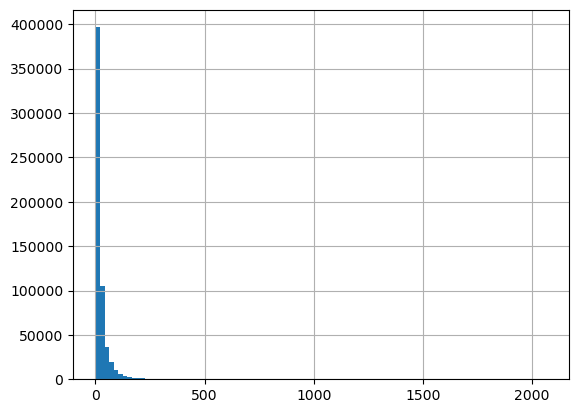

In [21]:
df['total ads'].hist(bins=100)

Анализ распределения тестовых групп.

<Axes: >

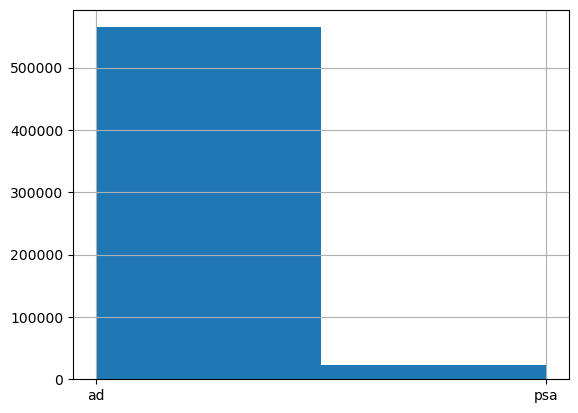

In [23]:
df['test group'].hist(bins=2)

Изучение распределения дней и часов с наибольшим количеством рекламы.

<Axes: >

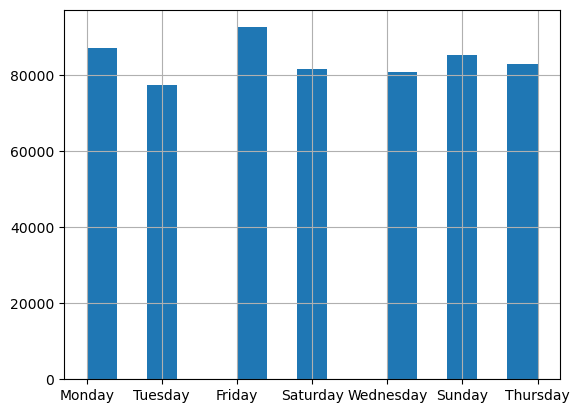

In [27]:
df['most ads day'].hist(bins=15)

<Axes: >

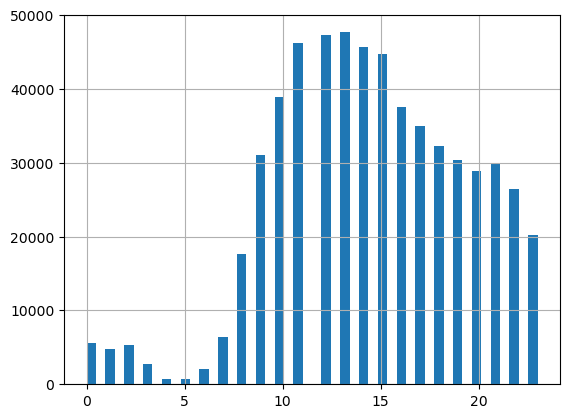

In [28]:
df['most ads hour'].hist(bins=48)

Вычисление и визуализация коэффициентов конверсии для тестовых групп.

In [32]:
df['converted'] = df['converted'].astype(int)

In [34]:
conversion_rates = df.groupby('test group')['converted'].agg(['count', 'sum']).reset_index()
conversion_rates.columns = ['test group', 'total_users', 'conversions']
conversion_rates['conversion_rate'] = conversion_rates['conversions'] / conversion_rates['total_users']
print(conversion_rates)

  test group  total_users  conversions  conversion_rate
0         ad       564577        14423             0.03
1        psa        23524          420             0.02


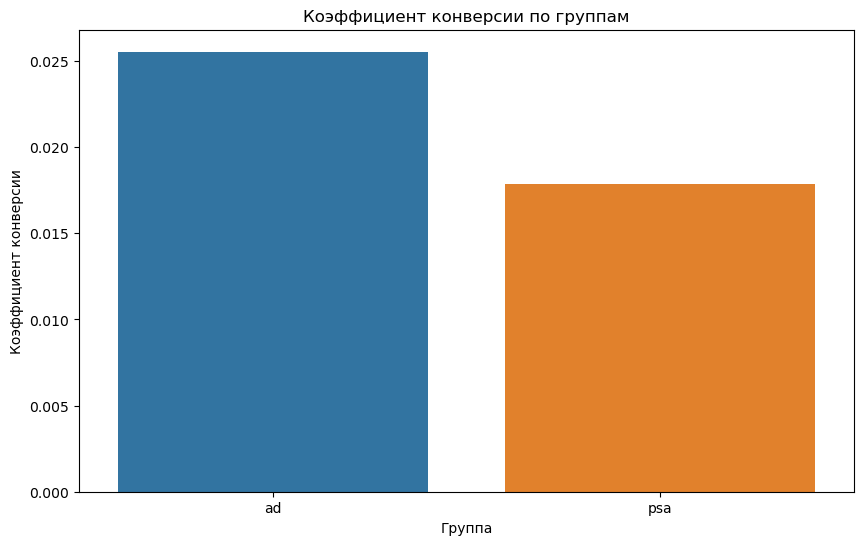

In [36]:
plt.figure(figsize=(10, 6))
sns.barplot(x='test group', y='conversion_rate', data=conversion_rates)
plt.title('Коэффициент конверсии по группам')
plt.xlabel('Группа')
plt.ylabel('Коэффициент конверсии')
plt.show()

Построение тепловой карты для корреляций признаков

<Axes: >

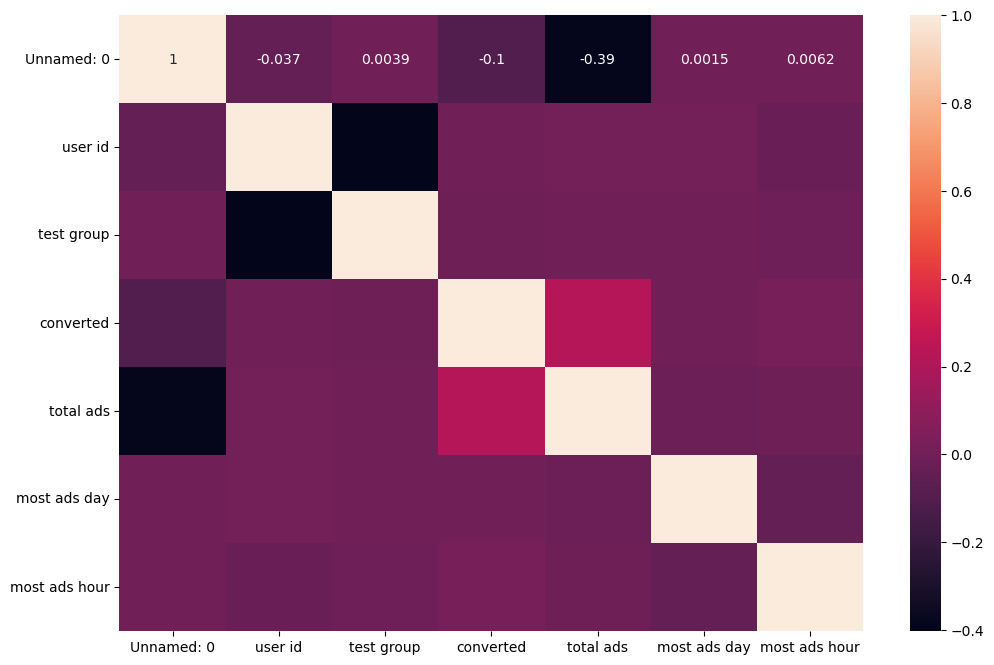

In [39]:
df['test group'] = df['test group'].astype('category').cat.codes
df['most ads day'] = df['most ads day'].astype('category').cat.codes
plt.figure(figsize=[12, 8])
sns.heatmap(df.corr(), annot=True)

# 3. A/A тестирование

Разделим наши данные на две группы

In [43]:
np.random.seed(42)
df['group'] = np.random.choice([1, 2], size=len(df), p=[0.5, 0.5])
df.head()

,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour,group
0,0,1069124,0,0,130,1,20,1
1,1,1119715,0,0,93,5,22,2
2,2,1144181,0,0,21,5,18,2
3,3,1435133,0,0,355,5,10,2
4,4,1015700,0,0,276,0,14,1


In [45]:
df_AA1 = df[(df.group == 1)].reset_index()
df_AA2 = df[(df.group == 2)].reset_index()

Проверим размеры групп.

In [48]:
print(df_AA1.shape)
print(df_AA2.shape)

(293836, 9)
(294265, 9)


Проведем t-тест для проверки различий между группами.

In [51]:
from scipy.stats import ttest_ind

In [53]:
alpha = 0.05

In [55]:
t_stat, p_value = ttest_ind(df_AA1['total ads'], df_AA2['total ads'])
print(t_stat, p_value)

-1.6404257729116736 0.10091720501009649


In [57]:
print(f'Значение p-value для групп А1 и A2: {p_value: .4f}')

Значение p-value для групп А1 и A2:  0.1009


In [59]:
if p_value > alpha:
    print('Статистичиески значимых различий между группами A1 и A2 не обнаружено.')
else:
    print('Обнаружены статистические значимые различия между группами A1 и A2.')


Статистичиески значимых различий между группами A1 и A2 не обнаружено.


4. Полезная визуализация А/А тестированияе

Гистограмма распределения значений в группах

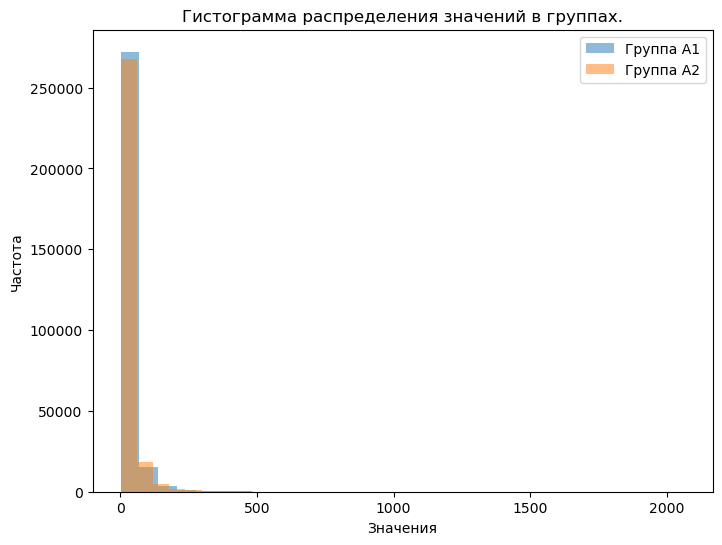

In [65]:
plt.figure(figsize=(8, 6))

plt.hist(df_AA1['total ads'], bins=30, alpha=0.5, label='Группа A1')
plt.hist(df_AA2['total ads'], bins=30, alpha=0.5, label='Группа A2')

plt.xlabel('Значения')
plt.ylabel('Частота')

plt.title('Гистограмма распределения значений в группах.')

plt.legend()

plt.show()

Сравнение конверсий между двумя группами.

In [77]:
conversion_ratesAA = df.groupby('group')['converted'].agg(['count', 'sum']).reset_index()
conversion_ratesAA.columns = ['group', 'total_users', 'conversions']
conversion_ratesAA['conversion_rate'] = conversion_ratesAA['conversions'] / conversion_ratesAA['total_users']
print(conversion_ratesAA)

   group  total_users  conversions  conversion_rate
0      1       293836         7370             0.03
1      2       294265         7473             0.03


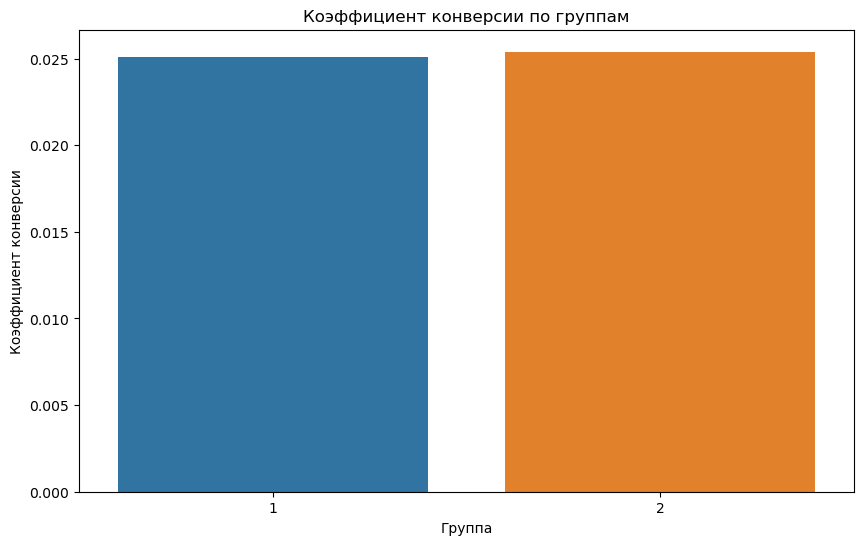

In [79]:
plt.figure(figsize=(10, 6))
sns.barplot(x='group', y='conversion_rate', data=conversion_ratesAA)
plt.title('Коэффициент конверсии по группам')
plt.xlabel('Группа')
plt.ylabel('Коэффициент конверсии')
plt.show()

# 5. Выводы и рекомендации 

В данном случае А/А тестирование подтверждает стабильность и надежность эксперимента, так как две контрольные группы не имеют статистически значимых различий между друг другом. Инструменты и методы тестирования работают корректно. Можно приступать к проведению А/В тестирования и быть уверенным в надежности и достоверности будущих результатов.

# 6. Анализ эффективности рекламы

Сравнение количества просмотров маркетинговых кампаний.

In [89]:
group_ad = df[(df['test group'] == 0)].reset_index()
group_ad

,index,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour,group
0,0,0,1069124,0,0,130,1,20,1
1,1,1,1119715,0,0,93,5,22,2
2,2,2,1144181,0,0,21,5,18,2
3,3,3,1435133,0,0,355,5,10,2
4,4,4,1015700,0,0,276,0,14,1
...,...,...,...,...,...,...,...,...,...
564572,588096,588096,1278437,0,0,1,5,23,1
564573,588097,588097,1327975,0,0,1,5,23,2
564574,588098,588098,1038442,0,0,3,5,23,2
564575,588099,588099,1496395,0,0,1,5,23,2


In [91]:
group_psa = df[(df['test group'] == 1)].reset_index()
group_psa

,index,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour,group
0,18,18,900681,1,0,248,2,19,1
1,38,38,905704,1,0,27,4,8,2
2,68,68,904595,1,0,13,5,19,1
3,140,140,901904,1,0,32,6,19,2
4,157,157,902234,1,0,105,5,19,2
...,...,...,...,...,...,...,...,...,...
23519,588052,588052,900959,1,0,16,5,22,2
23520,588063,588063,902828,1,0,3,5,22,1
23521,588066,588066,914578,1,0,1,5,22,1
23522,588069,588069,909042,1,0,6,5,22,2


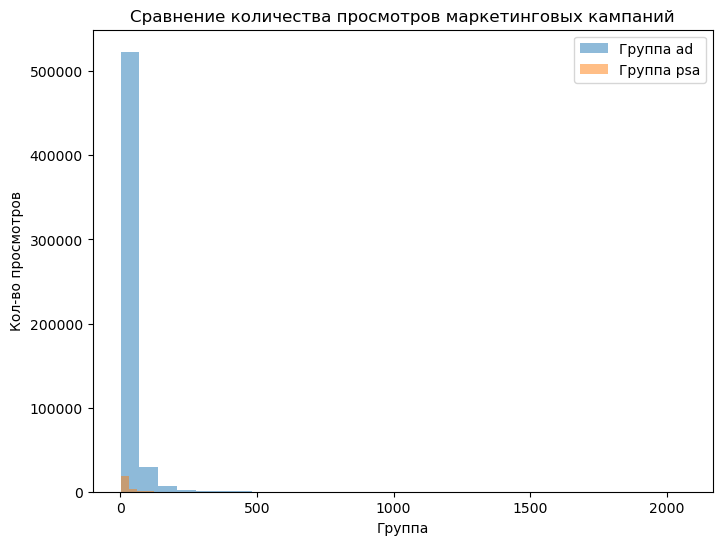

In [93]:
plt.figure(figsize=(8, 6))

plt.hist(group_ad['total ads'], bins=30, alpha=0.5, label='Группа ad')
plt.hist(group_psa['total ads'], bins=30, alpha=0.5, label='Группа psa')

plt.xlabel('Группа')
plt.ylabel('Кол-во просмотров')

plt.title('Сравнение количества просмотров маркетинговых кампаний')

plt.legend()

plt.show()

Изучение процента пользователей, которые конвертировались после просмотра объявления.

In [126]:
all_users = df['converted'].count()
all_users

588101

In [130]:
conversion_yes = df['converted'].sum()
conversion_yes

14843

In [136]:
conversion_rates = (conversion_yes / all_users) * 100
print(f'Процент пользователей, которые конвертировались после просмотра объявления составляет {conversion_rates} %')

Процент пользователей, которые конвертировались после просмотра объявления составляет 2.523886203220195 %


Изучение динамики конверсий в зависимости от группы (реклама или PSA).

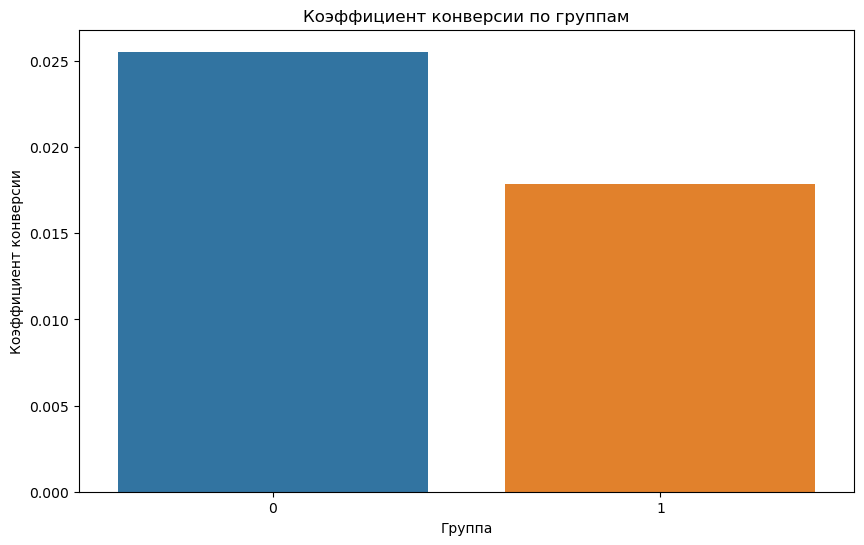

In [97]:
plt.figure(figsize=(10, 6))
sns.barplot(x='test group', y='conversion_rate', data=conversion_rates)
plt.title('Коэффициент конверсии по группам')
plt.xlabel('Группа')
plt.ylabel('Коэффициент конверсии')
plt.show()

# 7. Анализ времени просмотра объявлений

Изучение дней и часов, когда было совершено наибольшее количество конверсий.

In [157]:
ad_group_time = group_ad[group_ad['converted'] == 1].reset_index()
ad_group_time

,level_0,index,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour,group
0,15,15,15,1461774,0,1,9,6,18,1
1,42,44,44,1355531,0,1,265,5,12,1
2,104,107,107,1389878,0,1,1328,2,19,2
3,118,121,121,1475989,0,1,323,2,20,2
4,132,135,135,1241733,0,1,246,0,20,1
...,...,...,...,...,...,...,...,...,...,...
14418,562714,586037,586037,1473422,0,1,5,5,13,2
14419,562745,586073,586073,1259895,0,1,24,5,14,2
14420,562994,586343,586343,1371997,0,1,14,5,17,2
14421,563655,587069,587069,1586485,0,1,4,5,16,2


In [159]:
psa_group_time = group_psa[group_psa['converted'] == 1].reset_index()
psa_group_time

,level_0,index,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour,group
0,36,957,957,915026,1,1,88,3,19,1
1,102,2531,2531,904434,1,1,7,5,20,2
2,114,2744,2744,920737,1,1,77,1,13,2
3,115,2751,2751,904131,1,1,111,1,12,2
4,126,2979,2979,901749,1,1,364,0,21,2
...,...,...,...,...,...,...,...,...,...,...
415,21941,569821,569821,902040,1,1,13,0,19,2
416,22489,577022,577022,917817,1,1,7,3,13,2
417,22615,578515,578515,913311,1,1,2,3,19,2
418,23392,586818,586818,913022,1,1,11,5,15,1


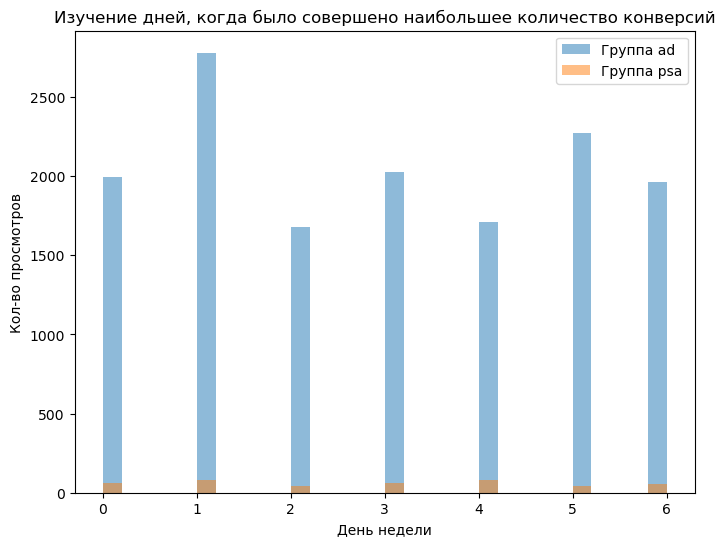

In [146]:
plt.figure(figsize=(8, 6))

plt.hist(ad_group_time['most ads day'], bins=30, alpha=0.5, label='Группа ad')
plt.hist(psa_group_time['most ads day'], bins=30, alpha=0.5, label='Группа psa')

plt.xlabel('День недели')
plt.ylabel('Кол-во просмотров')

plt.title('Изучение дней, когда было совершено наибольшее количество конверсий')

plt.legend()

plt.show()

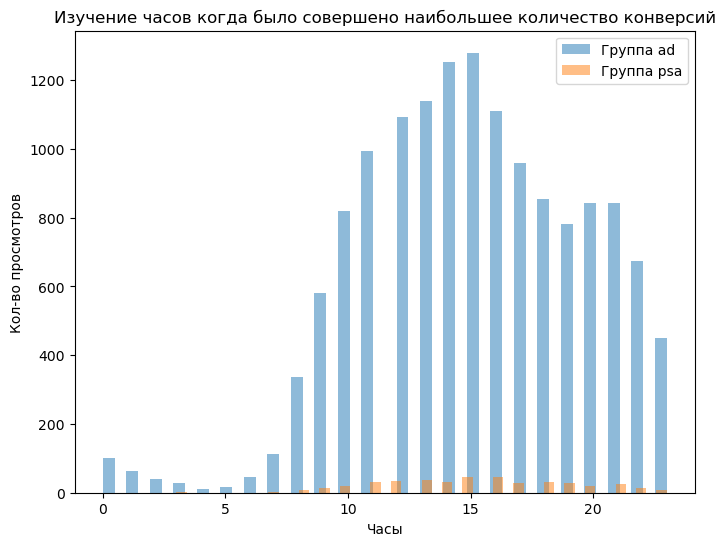

In [150]:
plt.figure(figsize=(8, 6))

plt.hist(ad_group_time['most ads hour'], bins=48, alpha=0.5, label='Группа ad')
plt.hist(psa_group_time['most ads hour'], bins=48, alpha=0.5, label='Группа psa')

plt.xlabel('Часы')
plt.ylabel('Кол-во просмотров')

plt.title('Изучение часов когда было совершено наибольшее количество конверсий')

plt.legend()

plt.show()

Оценка влияния времени дня на эффективность рекламы.

Можно сделать вывод, что наиболее эффективно реклама влияет на людей во вторник и субботу (Вероятно, потому что в понедельник никому некогда, а потом уже появляется время посидеть в интернете. А в субботу у большинства первый выходной день, все сидят в интернете, натыкаются на рекламу). Наиболее эффективно реклама влияет на людей после обеда, а именно, с 14 часов и до 17. Вечернее время тоже достаточно эффективное, но самый пик приходится на 15 часов.

# 8. Статистический анализ

Определение нормальности распределения конверсий в тестовых группах (Shapiro-Wilk тест)

In [195]:
# Проведение Shapiro-Wilk теста для группы ad
stat_ad, p_value_ad = stats.shapiro(ad_group_time['most ads hour'])
print(f'Группа ad: статистика={stat_ad}, p-значение={p_value_ad}')

# Проведение Shapiro-Wilk теста для группы psa
stat_psa, p_value_psa = stats.shapiro(psa_group_time['most ads hour'])
print(f'Группа psa: статистика={stat_psa}, p-значение={p_value_psa}')

Группа ad: статистика=0.9724313616752625, p-значение=1.401298464324817e-45
Группа psa: статистика=0.9817355871200562, p-значение=3.8127564039314166e-05


C:\Users\admin\anaconda3\Lib\site-packages\scipy\stats\_morestats.py:1882: UserWarning: p-value may not be accurate for N > 5000.
  warnings.warn("p-value may not be accurate for N > 5000.")


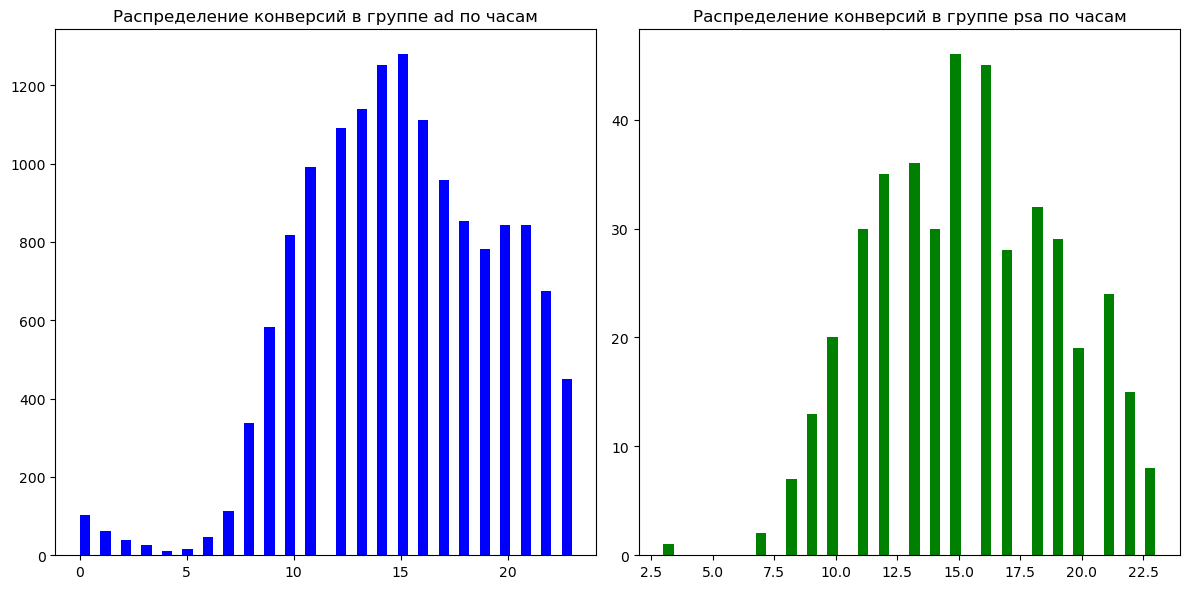

In [215]:
# Визуализация распределений
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.hist(ad_group_time['most ads hour'], bins=48, alpha=1, color='blue')
plt.title('Распределение конверсий в группе ad по часам')

plt.subplot(1, 2, 2)
plt.hist(psa_group_time['most ads hour'], bins=48, alpha=1, color='green')
plt.title('Распределение конверсий в группе psa по часам')

plt.tight_layout()
plt.show()

In [217]:
alpha = 0.05
if p_value_ad > alpha:
    print('Группа ad: Данные нормально распределены')
else:
    print('Группа ad: Данные НЕ нормально распределены')

if p_value_psa > alpha:
    print('Группа psa: Данные нормально распределены')
else:
    print('Группа psa: Данные НЕ нормально распределены')

Группа ad: Данные НЕ нормально распределены
Группа psa: Данные НЕ нормально распределены


Тест Левена для определения равенства дисперсий.

In [221]:
stat, p_value = levene(ad_group_time['most ads hour'], psa_group_time['most ads hour'])

In [223]:
print(f"Statistic: {stat}")
print(f"P-value: {p_value}")

Statistic: 14.316495963152617
P-value: 0.00015511214074764488


In [225]:
alpha = 0.05
if p_value > alpha:
    print("Нельзя отвергнуть нулевую гипотезу (дисперсии равны)")
else:
    print("Отвергаем нулевую гипотезу (дисперсии не равны)")

Отвергаем нулевую гипотезу (дисперсии не равны)


T-тест для сравнения средних значений конверсий в тестовых группах.

In [233]:
t1 = ttest_ind(ad_group_time['most ads hour'], psa_group_time['most ads hour'])
t1

TtestResult(statistic=-1.2664003954577532, pvalue=0.205389645400611, df=14841.0)

In [235]:
print(f"Statistic: {t1.statistic}")
print(f"P-value: {t1.pvalue}")

Statistic: -1.2664003954577532
P-value: 0.205389645400611


In [237]:
alpha = 0.05
if t1.pvalue > alpha:
    print('Статистичиески значимых различий между группами A и В не обнаружено.')
else:
    print('Обнаружены статистические значимые различия между группами A и В.')

Статистичиески значимых различий между группами A и В не обнаружено.


Вычисление и сравнение процента конверсий в обеих группах.

In [239]:
conversion_rates = df.groupby('test group')['converted'].agg(['count', 'sum']).reset_index()
conversion_rates.columns = ['test group', 'total_users', 'conversions']
conversion_rates['conversion_rate'] = conversion_rates['conversions'] / conversion_rates['total_users']
print(conversion_rates)

  test group  total_users  conversions  conversion_rate
0         ad       564577        14423             0.03
1        psa        23524          420             0.02


In [ ]:
Конверсия в рекламной группе чуточку выше

# 9. Проверка однородности дисперсии

In [241]:
stat, p_value = levene(ad_group_time['most ads hour'], psa_group_time['most ads hour'])

In [243]:
print(f"Statistic: {stat}")
print(f"P-value: {p_value}")

Statistic: 14.316495963152617
P-value: 0.00015511214074764488


In [245]:
alpha = 0.05
if p_value > alpha:
    print("Нельзя отвергнуть нулевую гипотезу (дисперсии равны)")
else:
    print("Отвергаем нулевую гипотезу (дисперсии не равны)")

Отвергаем нулевую гипотезу (дисперсии не равны)


# 10. Коэффициент конверсии

In [219]:
conversion_rates = df.groupby('test group')['converted'].agg(['count', 'sum']).reset_index()
conversion_rates.columns = ['test group', 'total_users', 'conversions']
conversion_rates['conversion_rate'] = conversion_rates['conversions'] / conversion_rates['total_users']
print(conversion_rates)

  test group  total_users  conversions  conversion_rate
0         ad       564577        14423             0.03
1        psa        23524          420             0.02


# 11. Выводы и рекомендации

Коммерческая реклама привлекает людей несколько больше, чем социальная. Но и на социальную люди обращают внимание и переходят по ней. Наиболее популярные дни для размещения любой рекламы: Вторник и Суббота. Самое ходовое время с 14 часов до 17 часов. Пик просмотров и переходов как по коммерческой так и по социальной рекламе в 15 часов. Конверсия может сильно зависить от дней недели и времени просмотра. Остальные значения из БД практически не влияют на этот показатель. Рекламные компании собирают намного больше просмотров, чем социальные, но в большей степени это связано с тем, что рекламных компаний размещается значительно больше. Если у компании имеется бюджет на то, чтобы вложиться в рекламы, конечно, это стоит делать. 